<h2>1. Predykcje</h2>
<p>Poniżej przedstawiam sposób korzystania z wytrenowanego modelu.</p>

In [1]:
from __future__ import division, print_function

import os.path
import random

import PIL

from PIL import Image
from matplotlib import pyplot as plt
from torchvision.transforms import transforms

from dxtorchx.prediction import TrainedModel

<h3>1.1 Definicja funkcji która:</h3>
<ul>
<li>wczytuje zdjęcie ze zbioru testowego po nazwie podanej jako parametr</li>
<li>wykonuje ewaluacje modelu na zdjęciu</li>
<li>wyśtwiela zdjęcie</li>
<li>nazwę schorzenia oraz jego diagnozę (y_true -> 0 - brak schorzenia, 1 - schorzenie występuje), zgodnie z dostarczoną etykietą</li>
<li>y_prob -> prawdopodobieństwo, że schorzenie występuje na zdjęciu jako wynik ewaluacji modelu</li>
<li>y_predicted -> klasyfikacja prawdopodobieństwa zgodnie z ustalonym (w poprzednim notebooku) optymalnym progiem dla danego schorzenia</li>
</ul>

In [2]:
def show_image_with_prediction(model, filename):
    image = PIL.Image.open("test_images/" + filename)
    predictions_df = model.predict_test_image(image, filename)

    # normalizacja obrazu
    normalizer = transforms.Compose([
        transforms.Resize(512),
        transforms.CenterCrop(448)
    ])

    fig, ax = plt.subplots(figsize=(8, 12))
    image = normalizer(image.convert("RGB"))
    ax.imshow(image)
    ax.set_title(f"Zdjęcie: {filename}", fontsize=12, pad=20)

    y_start = -0.08
    y_step = -0.05
    font = {'family': 'monospace', 'size': 10}

    for i in range(len(predictions_df)):
        row = predictions_df.iloc[i]
        class_part = f"{row['class_name'].ljust(20)}  y_prob = {row['y_prob']:.3f}"
        ax.text(0, y_start + i * y_step, class_part, ha='left', transform=ax.transAxes, fontdict=font, color='blue')
        correct = row['y_predicted'] == row['y_true']
        pred_text = f"  y_pred = {row['y_predicted']}  y_true = {row['y_true']}"
        color = 'green' if correct else 'red'
        ax.text(0.5, y_start + i * y_step, pred_text, ha='left', transform=ax.transAxes,
                fontdict=font, color=color)

    ax.axis('off')
    # plt.savefig(f"output/{filename}", dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()


<h3>1.2 Wczytanie 5 losowych zdjęć ze zbioru testowego</h3>

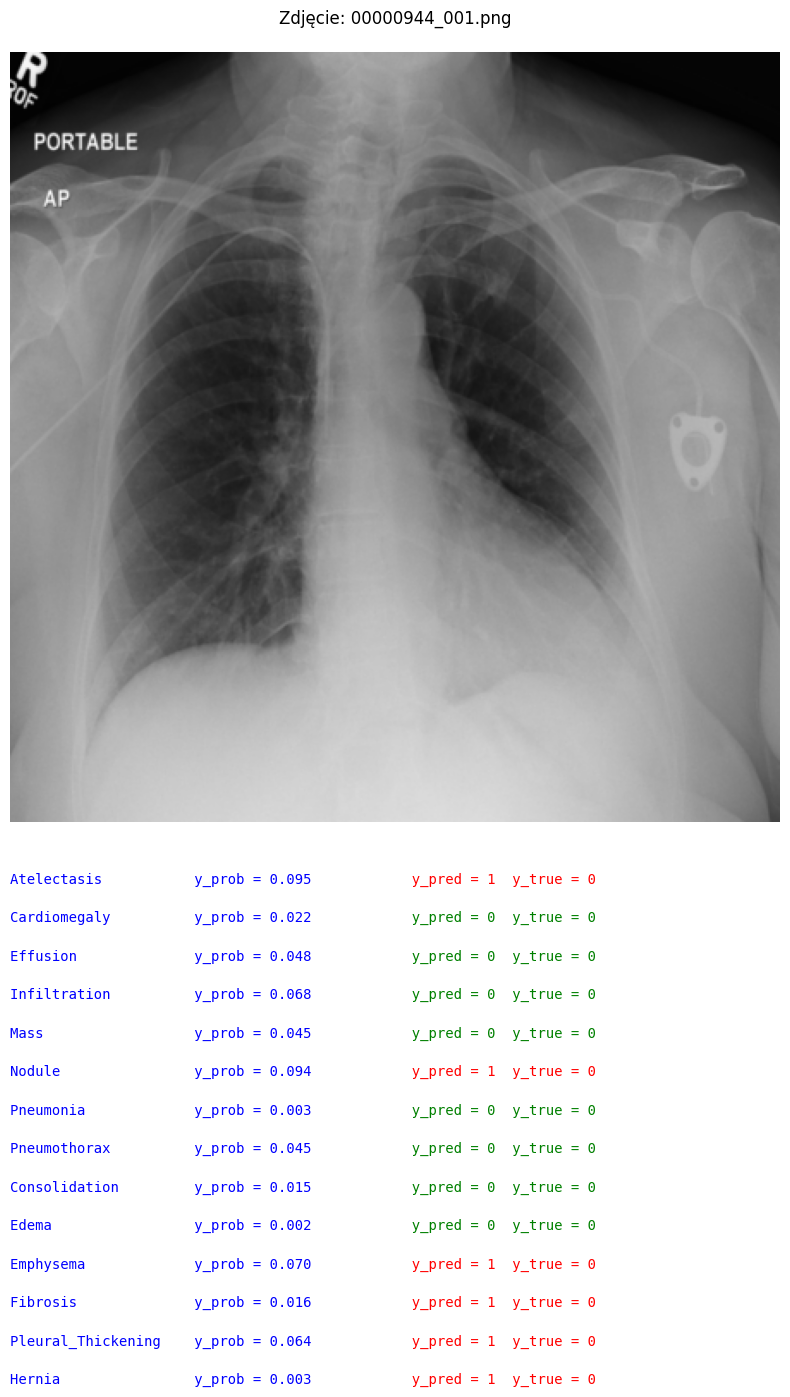

In [5]:
trained_model = TrainedModel()
test_images = os.listdir("test_images")
for test_file in random.sample(test_images, 1):
    show_image_with_prediction(trained_model, "00000944_001.png")
